# Women's representation in the Padma awards (1954–2021)

**Question.** Has the representation of women among India's national civilian awardees changed over time, and if so, is the change spread across fields or concentrated in a few?

**Data.** `national_awards_cleaned.csv`: 4,875 awardee records (name, award, field, state, year, year of birth, age at award) for Bharat Ratna and the three Padma awards (Vibhushan, Bhushan, Shri), 1954–2021. A Gender column is added by `gender_detect.py` (section 1).

**Hypotheses**

| | Statement |
|---|---|
| **H0** | Representation of women has not changed at all. |
| **H1** | Representation of women has increased, but it is concentrated within a select few fields. |
| **H2** | Representation of women has diversified, but not increased in magnitude across all fields. |
| **H3** | Representation of women has increased in magnitude across all fields and diversified as well. |

**Layout of the notebook**

1. Gender column (made by a separate script, with names checked by hand and on the web)
2. Women awardees per decade, by award (graph)
3. Women awardees per decade, by field (graphs)
4. Tests: did women's share of awardees change, overall and in each field?
5. Tests: where do women's awards go (concentration vs diversification)?
6. Verdict on H0–H3
7. Limitations

**Scope.** The descriptive graphs (sections 2–3) include Bharat Ratna. The hypothesis tests (sections 4–5) use only the three Padma awards, because the hypotheses are about those; Bharat Ratna has just 40 awards in 1960–2019, too few to test.

## 1. Adding a Gender column

The data has no gender field, so it is derived in a separate script, `gender_detect.py`, which is run once from the terminal (`python gender_detect.py`). It writes `awards_with_gender.csv`, which every later cell reads, so this notebook does not repeat the labelling. The script labels each name in three layers:

1. **Manual checks first** (`gender_overrides.csv`). Names that were checked by us win over everything else and are never changed by the script, so re-running it cannot undo a check.
2. **Honorifics.** A female honorific in the first four words (Smt., Shrimati, Kum., Kumari, Ms., Mrs., Miss, Begum, Begam, Bibi, Sadhvi, Sister, Mata, Mother, Maharani, Rajmata, Rajkumari, Pandita, Sushree, Lady, Her Highness) gives **W**. "Shri", "Sri", "Shree" or "Mr" as the first word gives **M**.
3. **Everything else is ambiguous and is not guessed.** Names with only "Dr.", "Prof.", "Pandit", a military rank and so on are not guessed from the title. The script prints them when it runs, and each one was settled by hand through the overrides file (layer 1). A bare "Dr." says nothing about gender.

**Which names were checked.** All 1,870 distinct names that had no explicit honorific (every "Dr.", "Prof.", "Pandit", "Ustad", rank and title other than Shri), plus the Shri names whose first name looks female to a name-gender lookup, were checked by us. We did this in two passes:

- **First pass:** each name was judged from the person (if known) or from the given name.
- **Second pass:** every woman found, and every low-confidence call, was checked by searching the web and reading a page that uses he/his or she/her for the same person (right field and award year). 96 names were confirmed this way. Each one has its page address and a quoted sentence in `gender_overrides.csv`.

The `Source` column in `gender_overrides.csv` records how each name was settled: `web_verified` (96), `female_title` (5: Bibi, Rajkumari, Pandita, Mother, Beegum), `knowledge` (1,753: the person or the given name is unambiguous, but no page was read), `name_only_unconfirmed` and `knowledge_unconfirmed` (15: could not be confirmed online, listed in section 7), `user_checked` (1: one name that web searches could not settle and the project author confirmed) and `manual_rule` (the duo rows and one false match).

**Special cases.** Eight award entries name two people (a "Duo"). Five of them are a woman and a man; these are marked `Mixed`. They are left out of the tests. "Shri Mata Prasad" had been labelled W only because "Mata" appears in the name; it is corrected to M.

**Effect of the checks.** The first version of the labels (honorifics only) missed women with a gender-neutral title. Among Padma awardees in 1960–2019, women number 692 after the checks instead of 625. The change is concentrated in recent decades, so the earlier results understated the rise:

| decade | 1960s | 1970s | 1980s | 1990s | 2000s | 2010s |
|---|---|---|---|---|---|---|
| women's share, honorifics only | 8.8% | 13.0% | 15.0% | 15.7% | 16.5% | 15.0% |
| women's share, after checks | 9.5% | 13.5% | 16.1% | 15.9% | 17.7% | 18.8% |

The cell below summarises how the labels were obtained.

In [1]:
import pandas as pd

# awards_with_gender.csv is produced by gender_detect.py (run it once from the terminal: python gender_detect.py).
# This cell only summarises how each Gender label was obtained.
genders = pd.read_csv("awards_with_gender.csv")
print(f"{len(genders)} awardee records")
display(pd.crosstab(genders["Gender_Source"], genders["Gender"].fillna("(blank)")))


4875 awardee records


Gender,M,Mixed,W
Gender_Source,,,
honorific,2208,0,706
manual_check,1875,5,81


## 2. Women awardees per decade, by award

This cell counts women awardees for each decade and award (Padma Vibhushan, Padma Bhushan, Padma Shri, Bharat Ratna), plus **Cumulated**, which adds all four. A decade is the calendar decade of the award year, so the 1950s start in 1954 and the 2020s contain only 2020–21. The table is saved as `decade_women_awardees.csv`, which the graph cell reads; the preview shows the first three decades.

In [2]:
import pandas as pd

# ==========================================
# 1. CONFIGURATION (Update column names to match your CSV)
# ==========================================
INPUT_FILE = "awards_with_gender.csv"
OUTPUT_FILE = "decade_women_awardees.csv"

YEAR_COL = "Year"  # Column name for the year of the award
AWARD_COL = "Award"  # Column name for the award type
GENDER_COL = "Gender"  # Column name for gender ('W' / 'M')

# ==========================================
# 2. LOAD & CLEAN DATA
# ==========================================
df = pd.read_csv(INPUT_FILE)

# Extract 4-digit year safely and convert to int
df["Clean_Year"] = (
    df[YEAR_COL].astype(str).str.extract(r"(\d{4})")[0].astype(float)
)
df = df.dropna(subset=["Clean_Year"])
df["Clean_Year"] = df["Clean_Year"].astype(int)

# Convert Year to Decade string (e.g., 1954 -> "1950s")
df["Decade"] = ((df["Clean_Year"] // 10) * 10).astype(str) + "s"


# Standardize Award Names
def standardize_award(award_str):
  if not isinstance(award_str, str):
    return None
  s = award_str.lower().strip()
  if "bharat ratna" in s:
    return "Bharat Ratna"
  elif "vibhushan" in s:
    return "Padma Vibhushan"
  elif "bhushan" in s:
    return "Padma Bhushan"
  elif "shri" in s or "shree" in s:
    return "Padma Shri"
  return None


df["Standard_Award"] = df[AWARD_COL].apply(standardize_award)
df = df.dropna(subset=["Standard_Award"])

# ==========================================
# 3. FILTER & COUNT WOMEN AWARDEES
# ==========================================
women_df = df[df[GENDER_COL] == "W"]

# Count per Decade and specific Award
award_counts = (
    women_df.groupby(["Decade", "Standard_Award"])
    .size()
    .reset_index(name="Women_Awardees")
    .rename(columns={"Standard_Award": "Award"})
)

# Count total (Cumulated) per Decade across all 4 awards (3 Padma + Bharat Ratna)
cumulated_counts = (
    women_df.groupby("Decade").size().reset_index(name="Women_Awardees")
)
cumulated_counts["Award"] = "Cumulated"

# Combine both tables
combined_counts = pd.concat(
    [award_counts, cumulated_counts], ignore_index=True
)

# ==========================================
# 4. BUILD COMPLETE GRID (5 ROWS PER DECADE)
# ==========================================
all_decades = sorted(df["Decade"].unique())
award_order = [
    "Padma Vibhushan",
    "Padma Bhushan",
    "Padma Shri",
    "Bharat Ratna",
    "Cumulated",
]

# Create full grid so every decade has all 5 rows in exact order
full_index = (
    pd.MultiIndex.from_product(
        [all_decades, award_order], names=["Decade", "Award"]
    )
    .to_frame()
    .reset_index(drop=True)
)

# Merge counts into the full grid
final_df = pd.merge(
    full_index, combined_counts, on=["Decade", "Award"], how="left"
)

# Fill missing counts with 0 and convert to integer
final_df["Women_Awardees"] = final_df["Women_Awardees"].fillna(0).astype(int)

# Save to CSV
final_df.to_csv(OUTPUT_FILE, index=False)

print(f"Saved successfully to '{OUTPUT_FILE}'!\n")
display(final_df.head(15))  # Previews the first 3 decades (15 rows)

Saved successfully to 'decade_women_awardees.csv'!



,Decade,Award,Women_Awardees
0,1950s,Padma Vibhushan,1
1,1950s,Padma Bhushan,13
2,1950s,Padma Shri,16
3,1950s,Bharat Ratna,0
4,1950s,Cumulated,30
5,1960s,Padma Vibhushan,2
6,1960s,Padma Bhushan,10
7,1960s,Padma Shri,39
8,1960s,Bharat Ratna,0
9,1960s,Cumulated,51


### Line graph: women awardees per decade, by award

/home/maulik/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


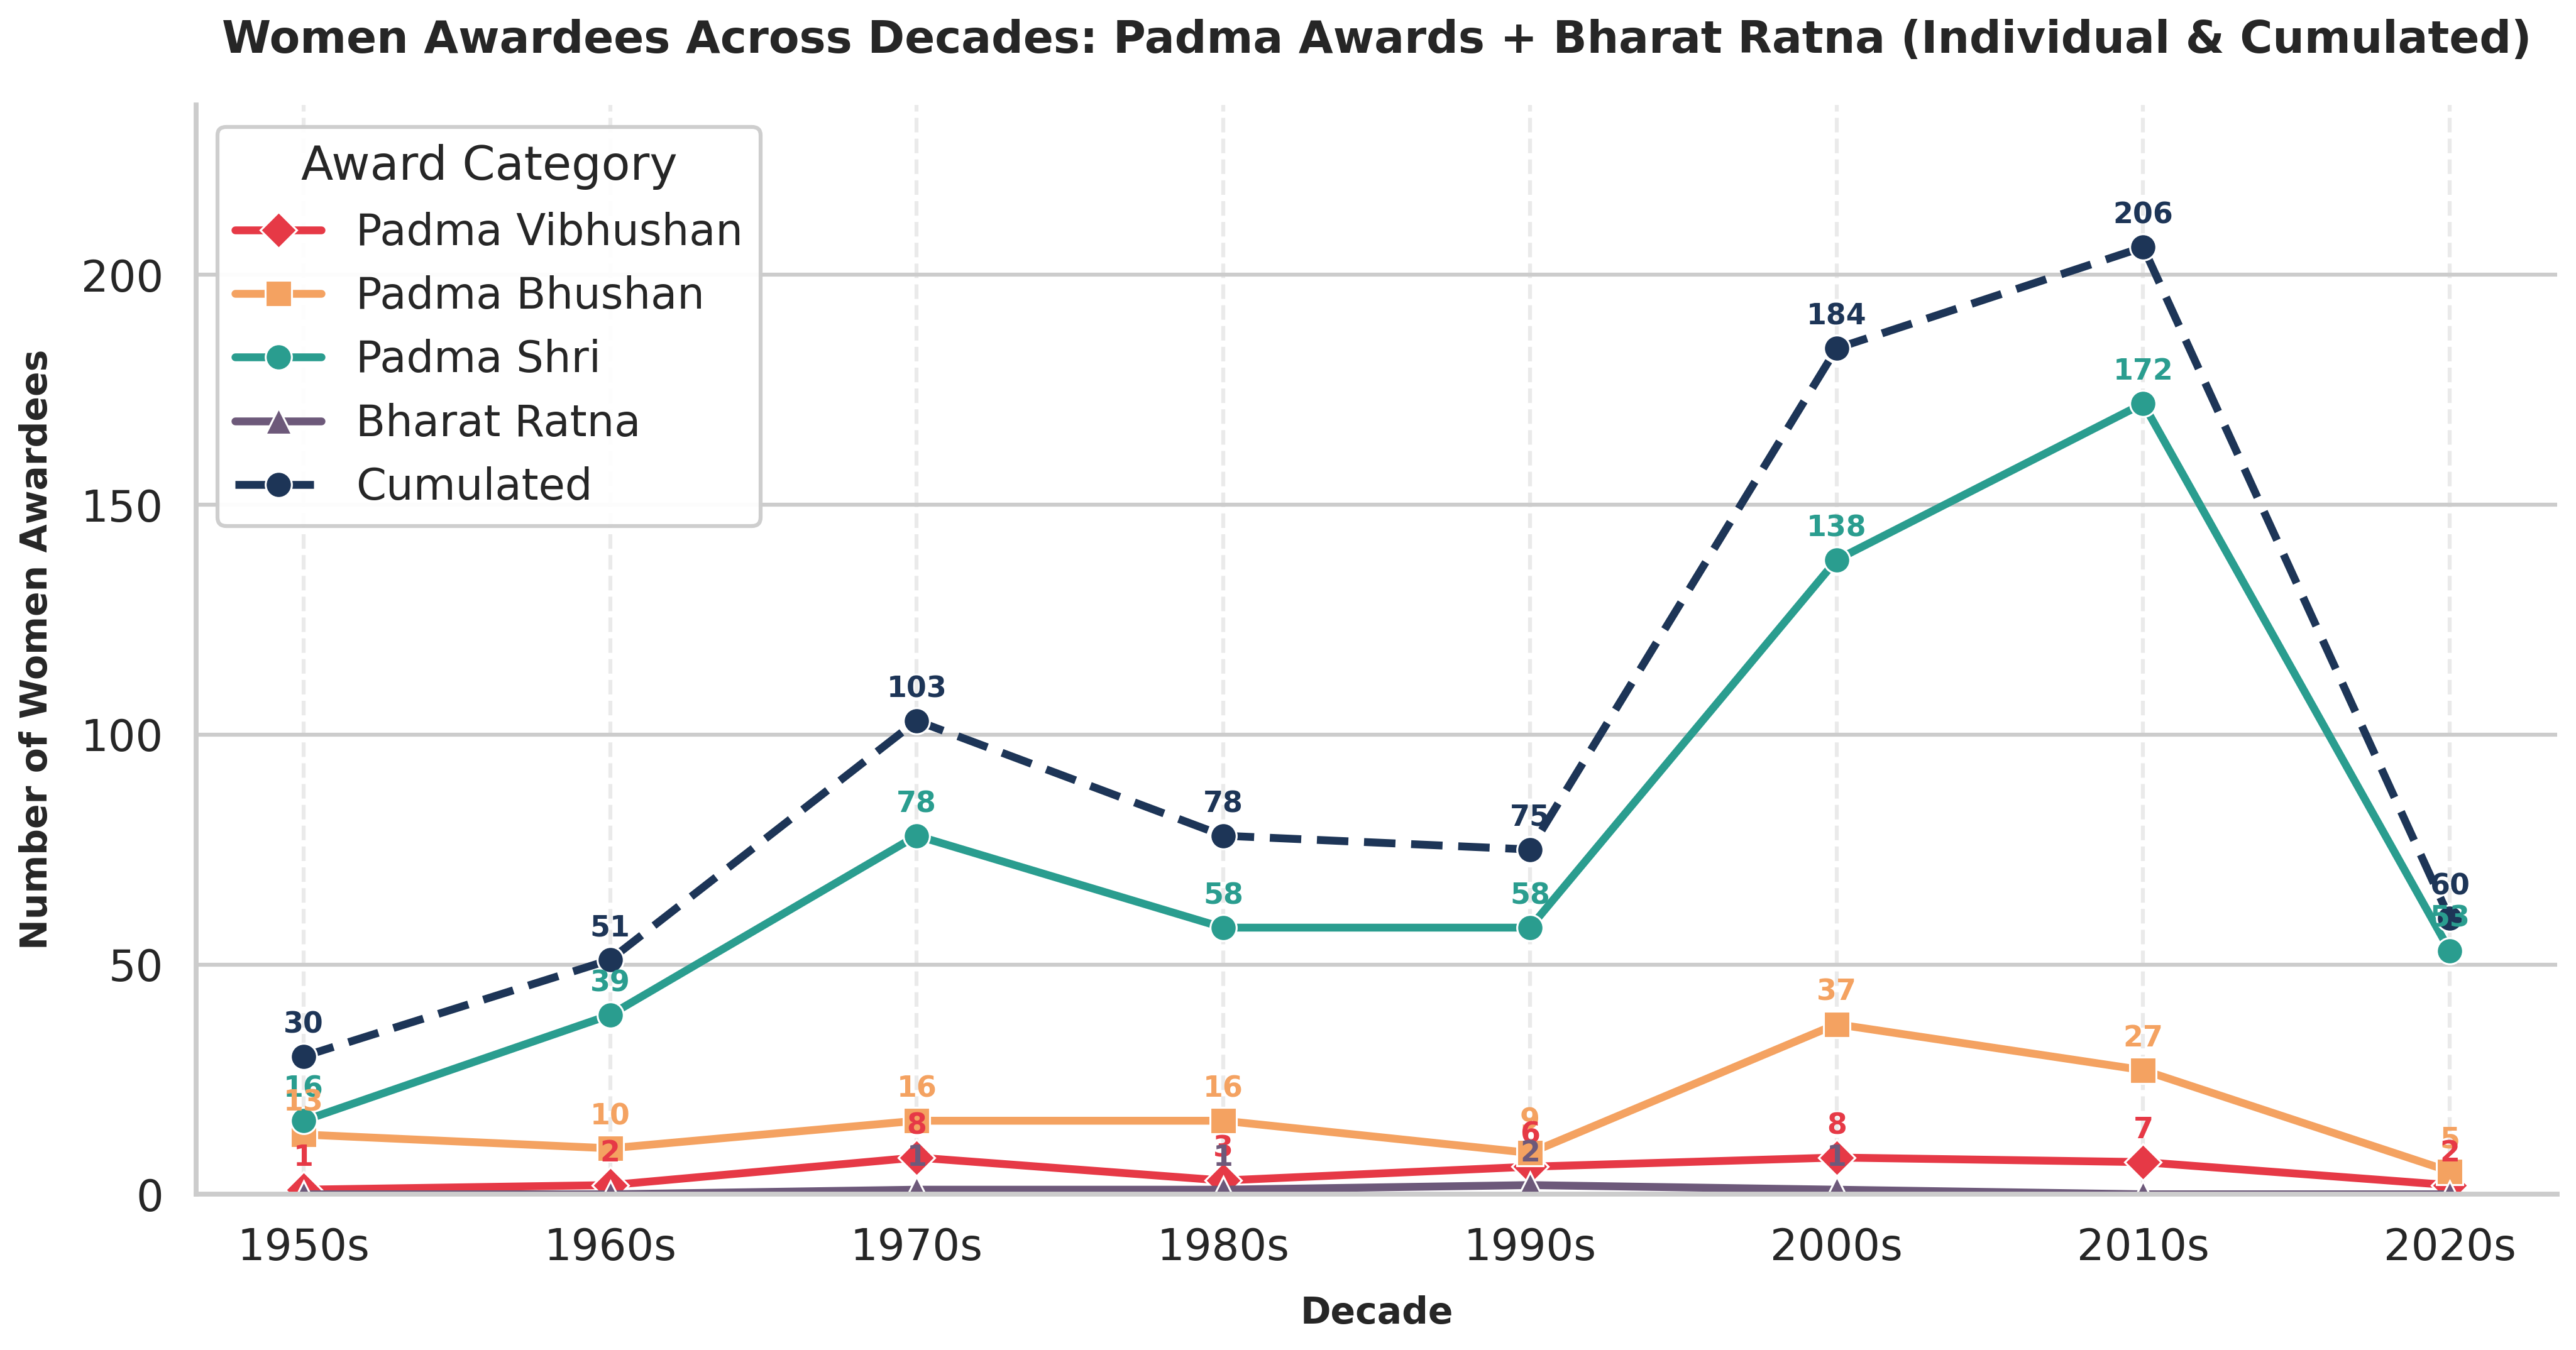

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("decade_women_awardees.csv")

sns.set_theme(style="whitegrid", context="talk")
plt.figure(figsize=(14, 7.5), dpi=300)

palette = {
    "Cumulated": "#1D3557",  # Deep Navy
    "Padma Shri": "#2A9D8F",  # Teal Green
    "Padma Bhushan": "#F4A261",  # Warm Orange
    "Padma Vibhushan": "#E63946",  # Crimson Red
    "Bharat Ratna": "#6D597A",  # Purple
}

# Plot all 5 lines (Cumulated is dashed to stand out from the 4 individual awards)
ax = sns.lineplot(
    data=df,
    x="Decade",
    y="Women_Awardees",
    hue="Award",
    style="Award",
    palette=palette,
    markers={
        "Cumulated": "o",
        "Padma Shri": "o",
        "Padma Bhushan": "s",
        "Padma Vibhushan": "D",
        "Bharat Ratna": "^",
    },
    dashes={
        "Cumulated": (4, 2),
        "Padma Shri": "",
        "Padma Bhushan": "",
        "Padma Vibhushan": "",
        "Bharat Ratna": "",
    },
    markersize=10,
    linewidth=3,
)

# Add data labels on every point
for award, color in palette.items():
  sub = df[df["Award"] == award].reset_index(drop=True)
  for idx, row in sub.iterrows():
    if award == "Bharat Ratna" and row["Women_Awardees"] == 0:
      continue  # skip the many zero labels so the plot stays readable
    ax.text(
        idx,
        row["Women_Awardees"] + (df["Women_Awardees"].max() * 0.025),
        f"{row['Women_Awardees']}",
        color=color,
        fontweight="bold",
        fontsize=11,
        ha="center",
    )

plt.title(
    "Women Awardees Across Decades: Padma Awards + Bharat Ratna (Individual & Cumulated)",
    fontsize=17,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Decade", fontsize=14, fontweight="bold", labelpad=10)
plt.ylabel(
    "Number of Women Awardees", fontsize=14, fontweight="bold", labelpad=10
)
plt.legend(
    title="Award Category",
    frameon=True,
    facecolor="white",
    framealpha=0.95,
    loc="upper left",
)

sns.despine(top=True, right=True)
plt.ylim(0, df["Women_Awardees"].max() * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()

**Reading the graph**

- **Cumulated** (all four awards): 30, 51, 103, 78, 75, 184, 206 from the 1950s to the 2010s. The 2020s point (60) covers only two years, so it is not a drop.
- **Padma Shri** supplies most women awardees (172 of the 206 in the 2010s). **Padma Bhushan** peaks at 37 in the 2000s. **Padma Vibhushan** never exceeds 8 per decade.
- **Bharat Ratna** has five women in total: Indira Gandhi (1971), Mother Teresa (1980), Aruna Asaf Ali (1997), M.S. Subbulakshmi (1998) and Lata Mangeshkar (2001). The line therefore stays between 0 and 2.
- **These are counts, not shares.** The total number of Padma awards per decade rose from about 460 in the 1990s to about 1,036 in the 2000s, so a rise in counts does not by itself show that women's share rose. Section 4 tests shares.

## 3. Women awardees per decade, by field

The same counts for each field (Art, Social Work, Literature and Education, Sports, Medicine, Science and Engineering, Public Affairs, Trade and Industry, Civil Service, Others). **Cumulated** again adds all four awards. The result is saved as `decade_field_women_awardees.csv`. The 2020s are left out of the graphs because the decade is incomplete. Graph 1 shows the four fields with the most women; graph 2 shows the remaining fields on a smaller y-axis.

In [4]:
import pandas as pd

# ==========================================
# 1. CONFIGURATION (Update column names if needed)
# ==========================================
INPUT_FILE = "awards_with_gender.csv"
OUTPUT_FILE = "decade_field_women_awardees.csv"

YEAR_COL = "Year"
AWARD_COL = "Award"
GENDER_COL = "Gender"
FIELD_COL = "Field"  # Column name for the field/discipline

# ==========================================
# 2. LOAD & CLEAN DATA
# ==========================================
df = pd.read_csv(INPUT_FILE)

# Extract 4-digit year and convert to int
df["Clean_Year"] = (
    df[YEAR_COL].astype(str).str.extract(r"(\d{4})")[0].astype(float)
)
df = df.dropna(subset=["Clean_Year"])
df["Clean_Year"] = df["Clean_Year"].astype(int)

# Convert Year to Decade string (e.g., 1954 -> "1950s")
df["Decade"] = ((df["Clean_Year"] // 10) * 10).astype(str) + "s"


# Standardize Award Names
def standardize_award(award_str):
  if not isinstance(award_str, str):
    return None
  s = award_str.lower().strip()
  if "bharat ratna" in s:
    return "Bharat Ratna"
  elif "vibhushan" in s:
    return "Padma Vibhushan"
  elif "bhushan" in s:
    return "Padma Bhushan"
  elif "shri" in s or "shree" in s:
    return "Padma Shri"
  return None


df["Standard_Award"] = df[AWARD_COL].apply(standardize_award)
df = df.dropna(subset=["Standard_Award"])

# Ensure field column exists and clean up whitespace/nulls
if FIELD_COL not in df.columns:
  raise ValueError(
      f"Error: Column '{FIELD_COL}' not found in your CSV! Available columns:"
      f" {list(df.columns)}"
  )

df[FIELD_COL] = df[FIELD_COL].astype(str).str.strip()
df = df[df[FIELD_COL].str.lower() != "nan"]

# ==========================================
# 3. FILTER WOMEN & COUNT BY FIELD, DECADE, AWARD
# ==========================================
women_df = df[df[GENDER_COL] == "W"]

# Count specific awards per Field and Decade
award_counts = (
    women_df.groupby([FIELD_COL, "Decade", "Standard_Award"])
    .size()
    .reset_index(name="Women_Awardees")
    .rename(columns={"Standard_Award": "Award"})
)

# Count Cumulated total per Field and Decade across all 4 awards (3 Padma + Bharat Ratna)
cumulated_counts = (
    women_df.groupby([FIELD_COL, "Decade"])
    .size()
    .reset_index(name="Women_Awardees")
)
cumulated_counts["Award"] = "Cumulated"

# Combine both count sets
combined_counts = pd.concat(
    [award_counts, cumulated_counts], ignore_index=True
)

# ==========================================
# 4. BUILD COMPLETE MULTI-INDEX GRID
# ==========================================
all_fields = sorted(women_df[FIELD_COL].unique())
all_decades = sorted(df["Decade"].unique())
award_order = [
    "Padma Vibhushan",
    "Padma Bhushan",
    "Padma Shri",
    "Bharat Ratna",
    "Cumulated",
]

# Create a complete grid of every Field x Decade x Award combination
full_index = (
    pd.MultiIndex.from_product(
        [all_fields, all_decades, award_order],
        names=[FIELD_COL, "Decade", "Award"],
    )
    .to_frame()
    .reset_index(drop=True)
)

# Merge actual counts into the full grid
final_df = pd.merge(
    full_index, combined_counts, on=[FIELD_COL, "Decade", "Award"], how="left"
)

# Fill missing counts with 0 and convert to integer
final_df["Women_Awardees"] = final_df["Women_Awardees"].fillna(0).astype(int)

# Sort strictly by Field, then Decade chronologically, then Award order
award_cat = pd.CategoricalDtype(categories=award_order, ordered=True)
final_df["Award"] = final_df["Award"].astype(award_cat)

final_df = final_df.sort_values(by=[FIELD_COL, "Decade", "Award"]).reset_index(
    drop=True
)

# Save to CSV
final_df.to_csv(OUTPUT_FILE, index=False)

print(
    f"Success! Saved sorted breakdown by Field and Decade to '{OUTPUT_FILE}'!\n"
)
display(final_df.head(15))  # Previews the first 15 rows (Art for the first 3 decades)

Success! Saved sorted breakdown by Field and Decade to 'decade_field_women_awardees.csv'!



,Field,Decade,Award,Women_Awardees
0,Art,1950s,Padma Vibhushan,0
1,Art,1950s,Padma Bhushan,3
2,Art,1950s,Padma Shri,2
3,Art,1950s,Bharat Ratna,0
4,Art,1950s,Cumulated,5
5,Art,1960s,Padma Vibhushan,0
6,Art,1960s,Padma Bhushan,3
7,Art,1960s,Padma Shri,12
8,Art,1960s,Bharat Ratna,0
9,Art,1960s,Cumulated,15


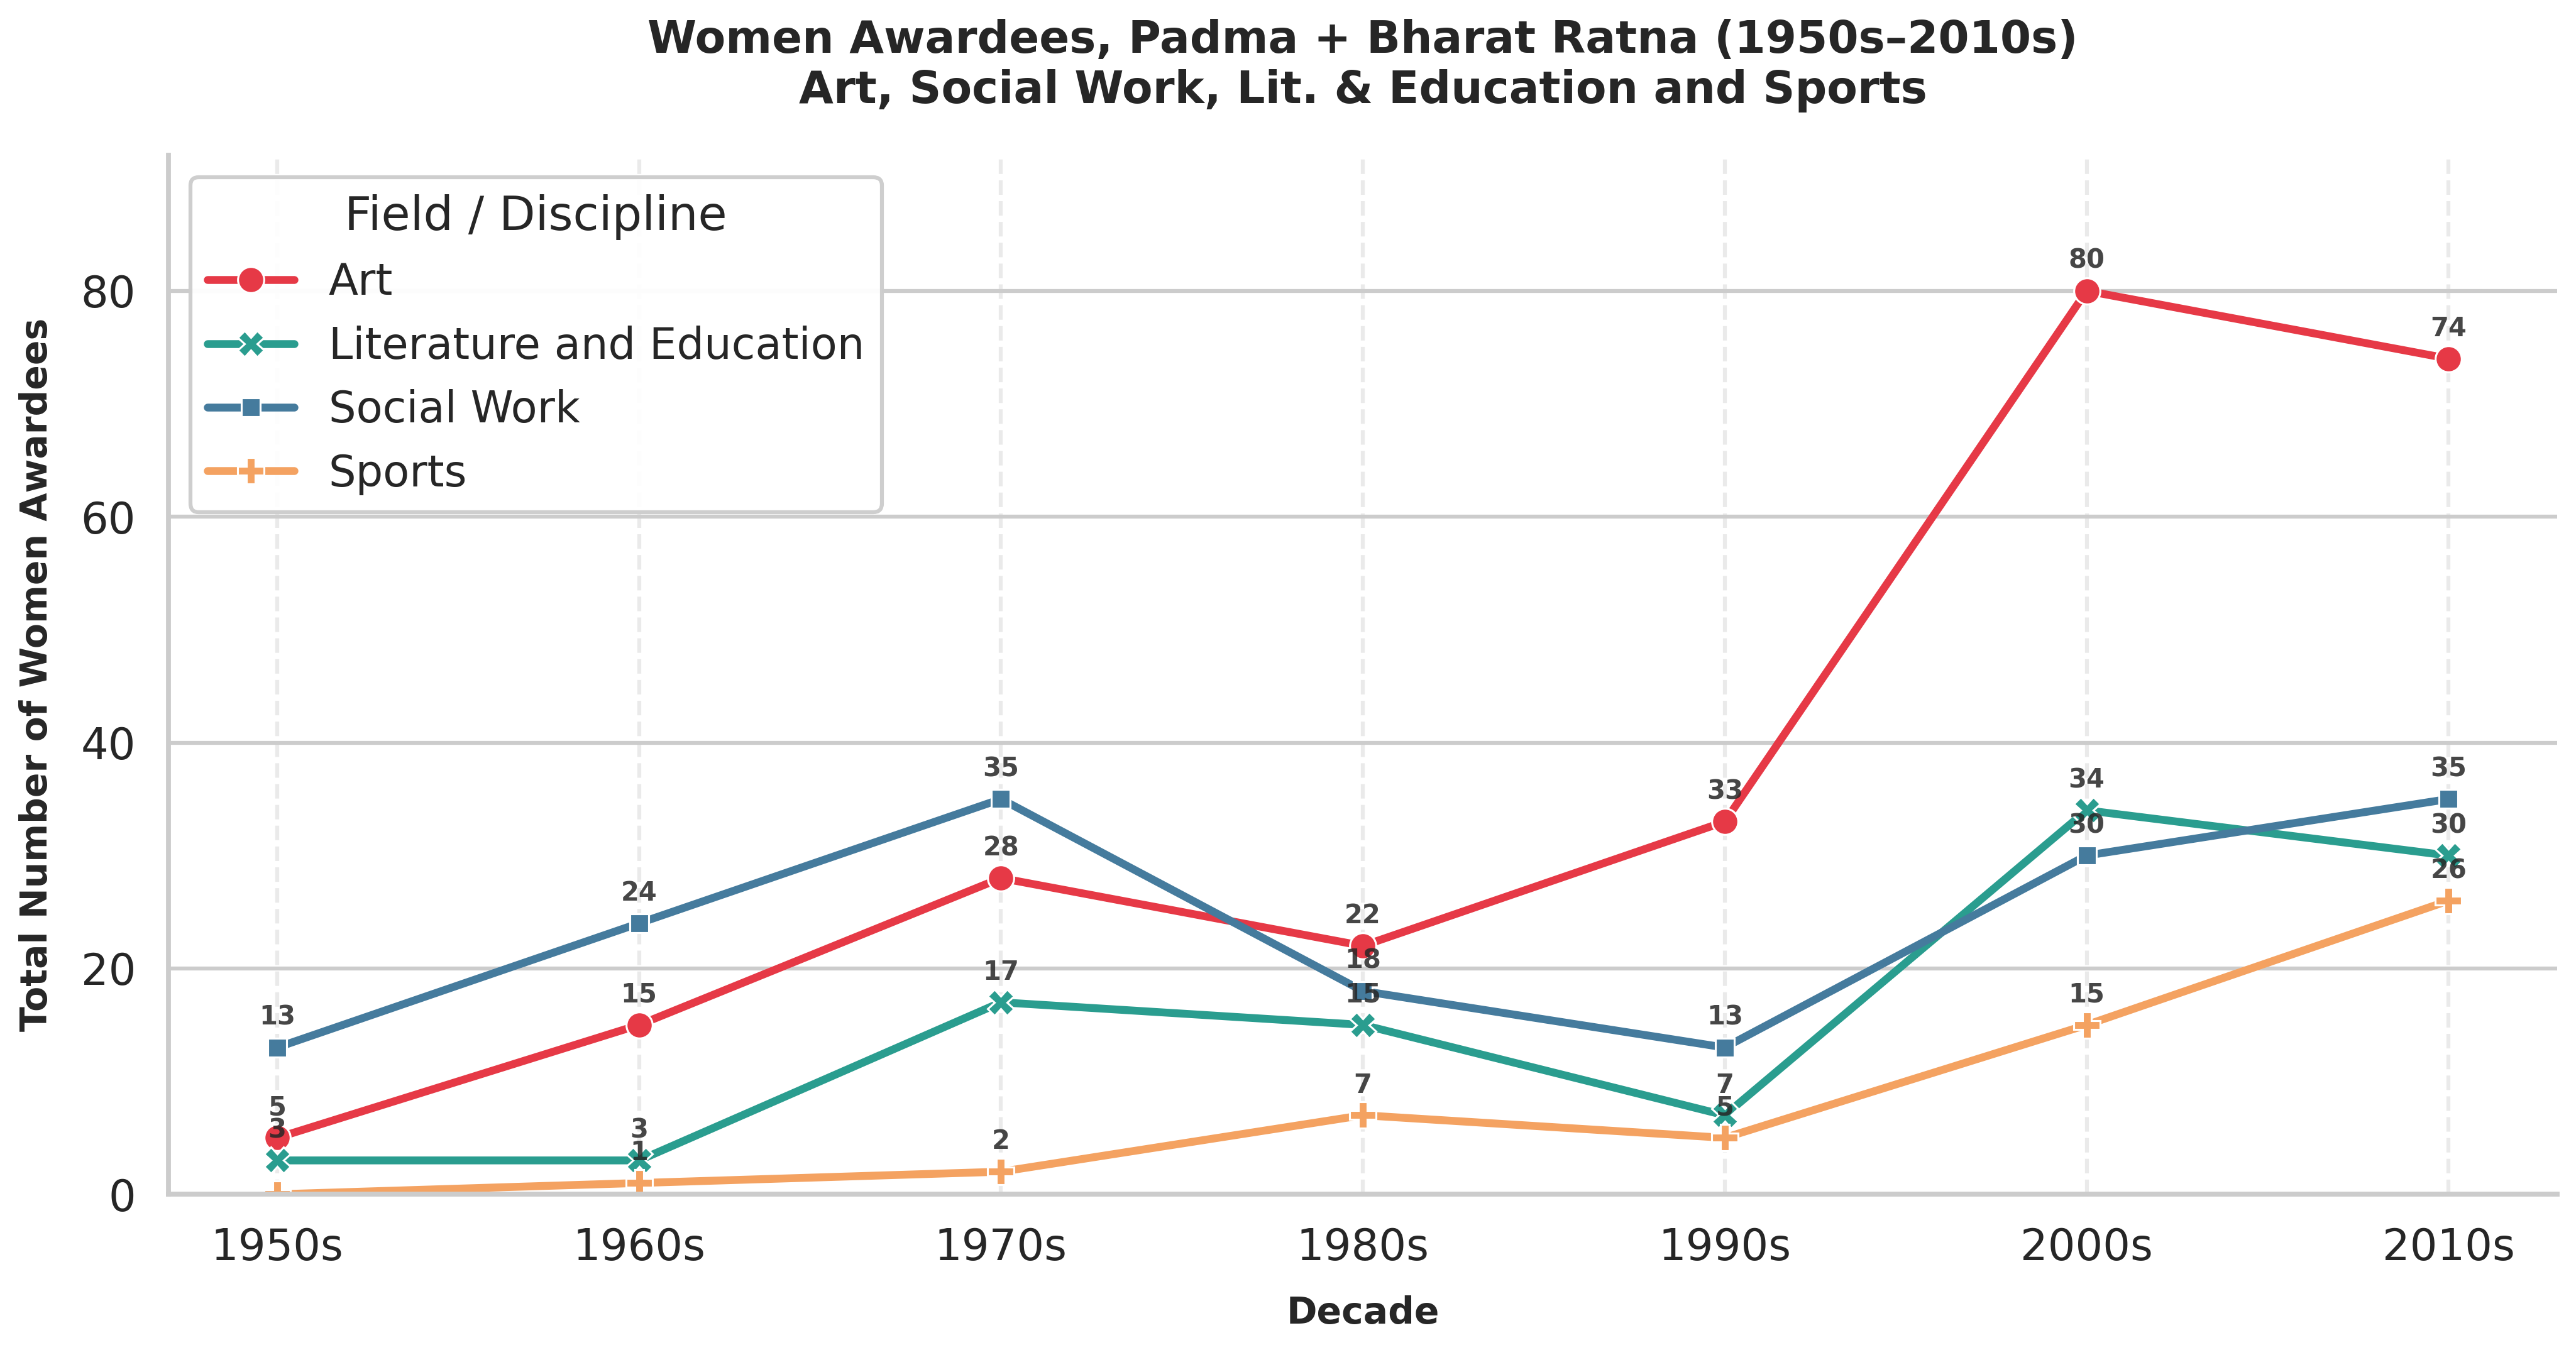

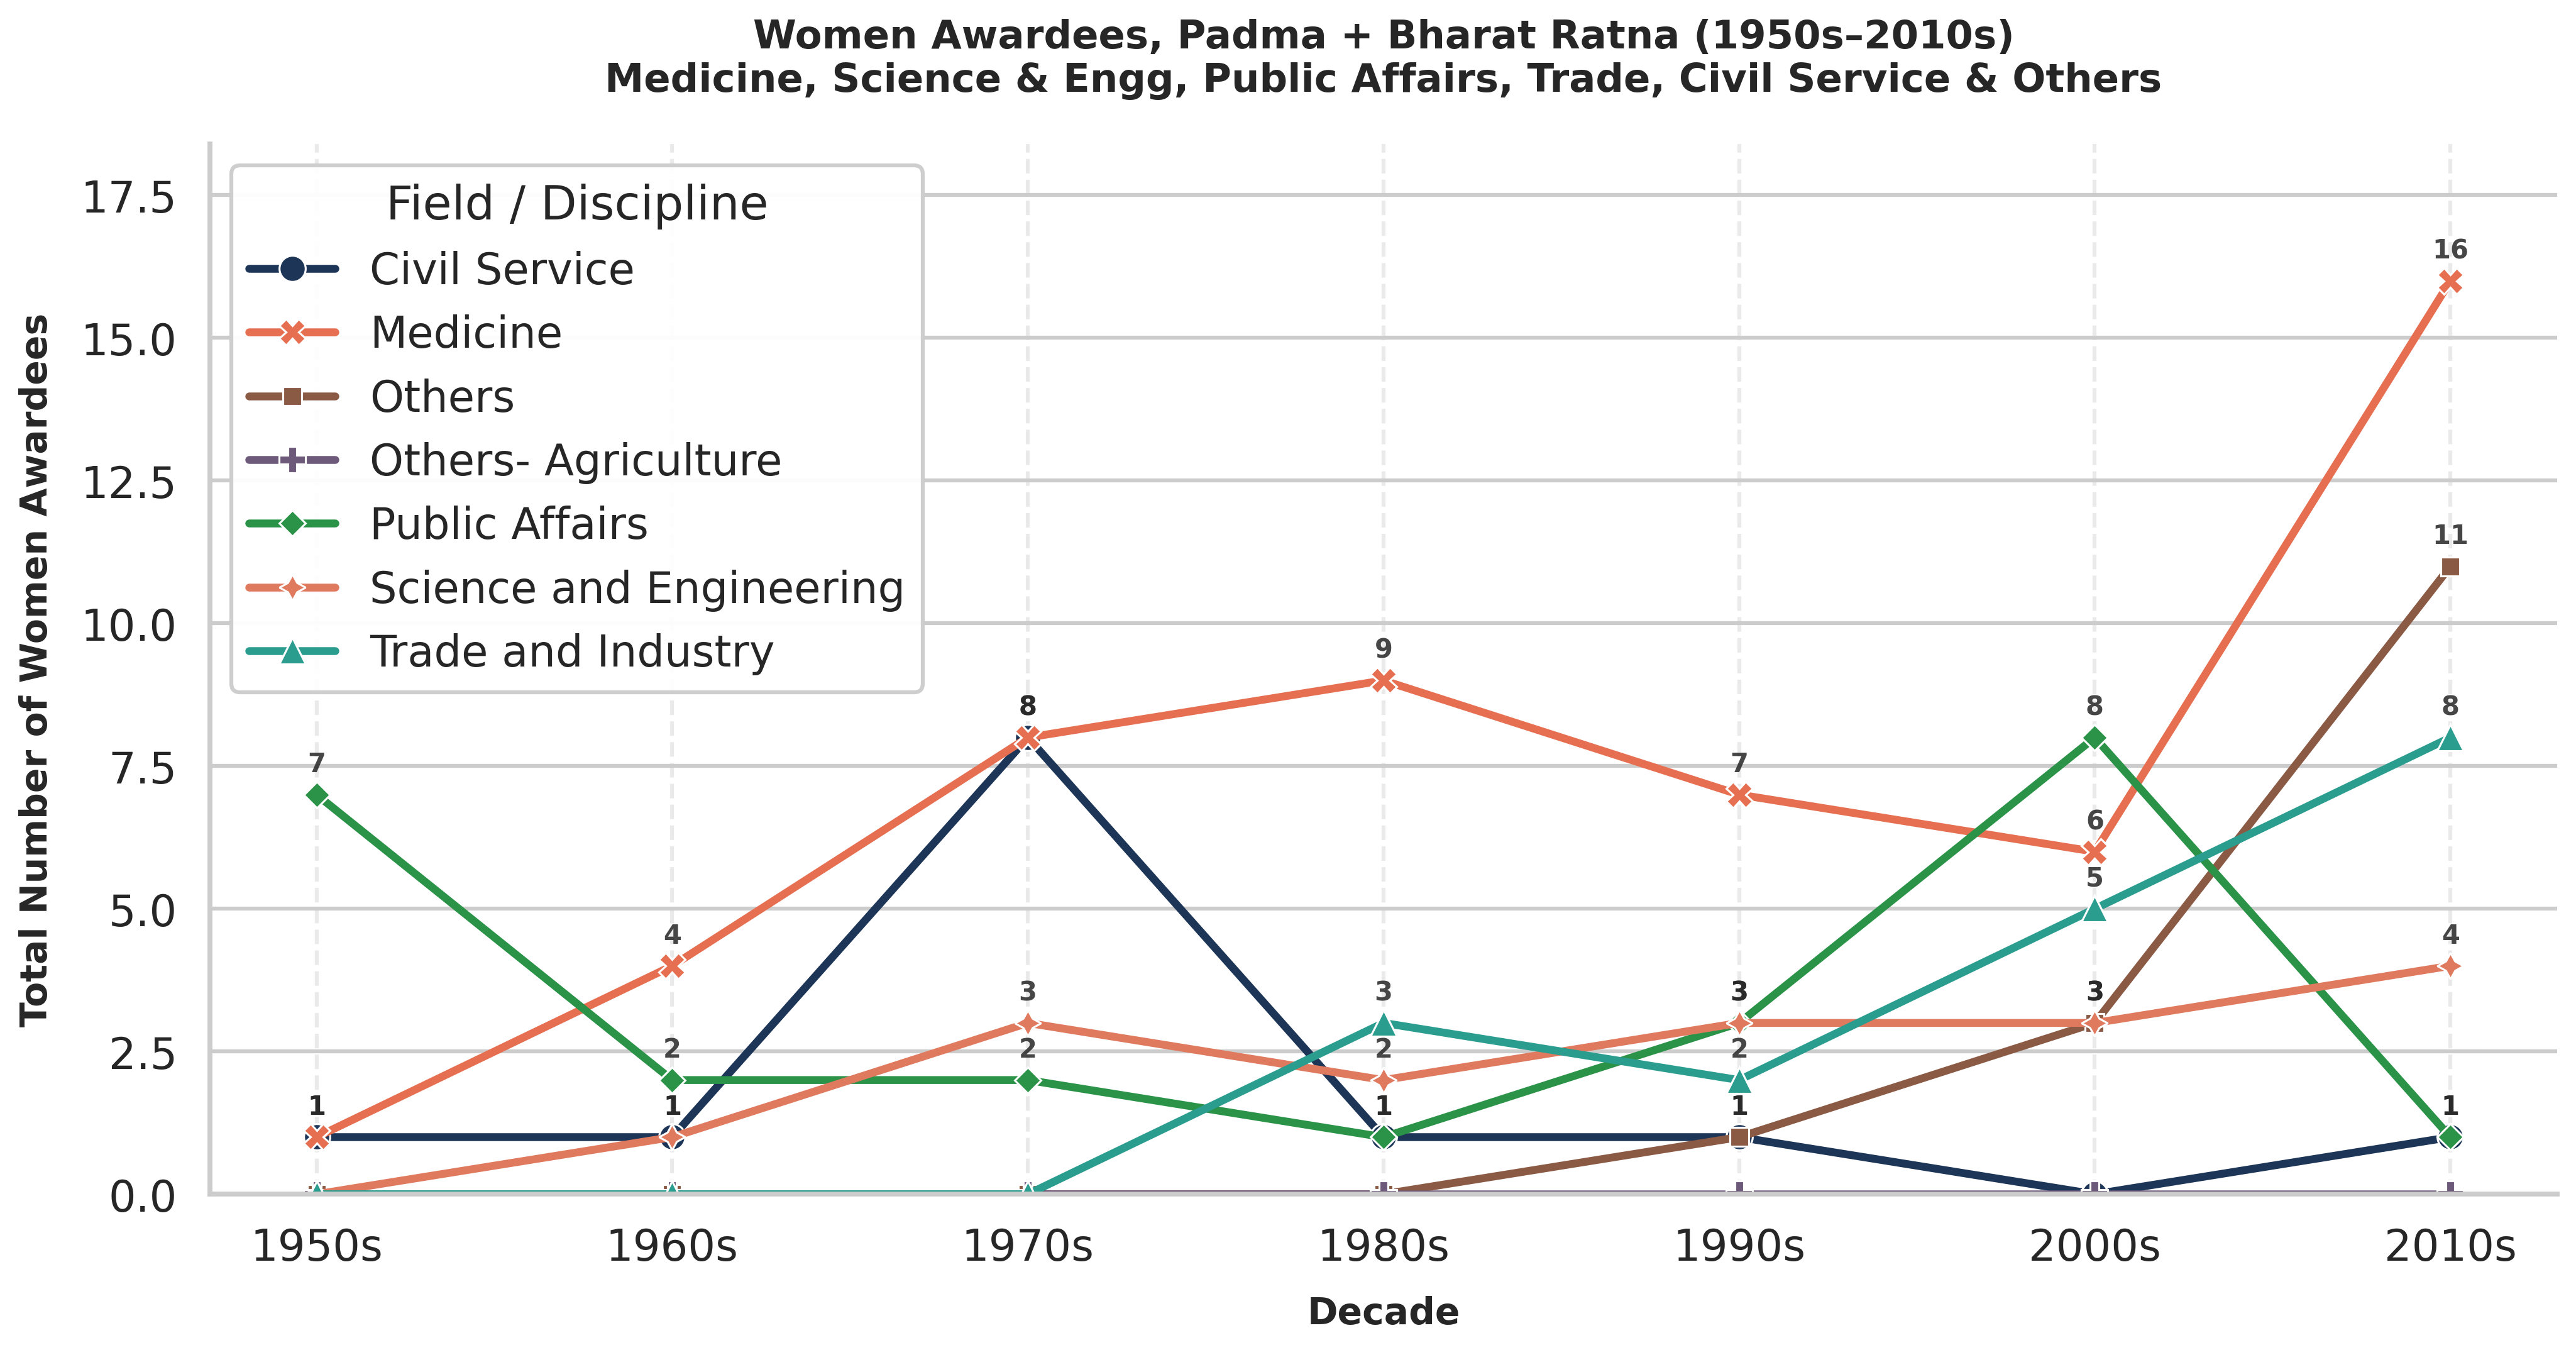

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ==========================================
# 1. LOAD DATA, REMOVE 2020s & FILTER CUMULATED
# ==========================================
INPUT_FILE = "decade_field_women_awardees.csv"
df = pd.read_csv(INPUT_FILE)

# Filter for 'Cumulated' total per field AND exclude the '2020s' decade
cumulated_df = df[
    (df["Award"] == "Cumulated") & (df["Decade"] != "2020s")
].copy()


# Helper function to match the first 4 fields regardless of "and" vs "&" or capitalization
def is_in_group_1(field_name):
  if not isinstance(field_name, str):
    return False
  f = field_name.lower().replace("&", "and").strip()
  group_1_targets = [
      "art",
      "social work",
      "literature and education",
      "sports",
  ]
  return f in group_1_targets


# Split into the two requested groups
mask_group_1 = cumulated_df["Field"].apply(is_in_group_1)
df_group_1 = cumulated_df[mask_group_1].copy()
df_group_2 = cumulated_df[~mask_group_1].copy()

# Set modern styling
sns.set_theme(style="whitegrid", context="talk")

# ==========================================
# GRAPH 1: Art, Social Work, Literature & Education, Sports
# ==========================================
plt.figure(figsize=(14, 7.5), dpi=300)

palette_1 = ["#E63946", "#2A9D8F", "#457B9D", "#F4A261"]
decades_order_1 = sorted(df_group_1["Decade"].unique())

ax1 = sns.lineplot(
    data=df_group_1,
    x="Decade",
    y="Women_Awardees",
    hue="Field",
    style="Field",
    palette=palette_1[: df_group_1["Field"].nunique()],
    markers=True,
    dashes=False,
    markersize=10,
    linewidth=3,
)

# Add data labels on points for Graph 1
max_y1 = df_group_1["Women_Awardees"].max()
for _, row in df_group_1.iterrows():
  if row["Women_Awardees"] > 0:
    x_idx = decades_order_1.index(row["Decade"])
    ax1.text(
        x_idx,
        row["Women_Awardees"] + (max_y1 * 0.025),
        f"{int(row['Women_Awardees'])}",
        fontsize=10,
        fontweight="bold",
        ha="center",
        alpha=0.85,
    )

plt.title(
    "Women Awardees, Padma + Bharat Ratna (1950s–2010s)\nArt, Social Work,"
    " Lit. & Education and Sports",
    fontsize=17,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Decade", fontsize=14, fontweight="bold", labelpad=10)
plt.ylabel(
    "Total Number of Women Awardees", fontsize=14, fontweight="bold", labelpad=10
)
plt.legend(
    title="Field / Discipline",
    frameon=True,
    facecolor="white",
    framealpha=0.95,
    loc="upper left",
)

sns.despine(top=True, right=True)
plt.ylim(0, max_y1 * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()

# ==========================================
# GRAPH 2: Remaining 6 Fields
# ==========================================
plt.figure(figsize=(14, 7.5), dpi=300)

palette_2 = [
    "#1D3557", "#E76F51", "#8A5A44", "#6D597A", "#2B9348", "#E07A5F", "#2A9D8F",
]  # 7 colours: group 2 has 7 field labels
decades_order_2 = sorted(df_group_2["Decade"].unique())

ax2 = sns.lineplot(
    data=df_group_2,
    x="Decade",
    y="Women_Awardees",
    hue="Field",
    style="Field",
    palette=palette_2[: df_group_2["Field"].nunique()],
    markers=True,
    dashes=False,
    markersize=10,
    linewidth=3,
)

# Add data labels on points for Graph 2
max_y2 = df_group_2["Women_Awardees"].max()
for _, row in df_group_2.iterrows():
  if row["Women_Awardees"] > 0:
    x_idx = decades_order_2.index(row["Decade"])
    ax2.text(
        x_idx,
        row["Women_Awardees"] + (max_y2 * 0.025),
        f"{int(row['Women_Awardees'])}",
        fontsize=10,
        fontweight="bold",
        ha="center",
        alpha=0.85,
    )

plt.title(
    "Women Awardees, Padma + Bharat Ratna (1950s–2010s)\nMedicine, Science &"
    " Engg, Public Affairs, Trade, Civil Service & Others",
    fontsize=15,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Decade", fontsize=14, fontweight="bold", labelpad=10)
plt.ylabel(
    "Total Number of Women Awardees", fontsize=14, fontweight="bold", labelpad=10
)
plt.legend(
    title="Field / Discipline",
    frameon=True,
    facecolor="white",
    framealpha=0.95,
    loc="upper left",
)

sns.despine(top=True, right=True)
plt.ylim(0, max(5, max_y2 * 1.15))
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()

**Reading the graphs** (women awardees per decade, 1950s to 2010s)

*Graph 1: the four largest fields*

- **Art:** 5, 15, 28, 22, 33, 80, 74. It is the largest field for women from the 1990s on.
- **Social Work:** 13, 24, 35, 18, 13, 30, 35. It is high in the 1970s and 2010s with a dip in between.
- **Literature and Education:** 3, 3, 17, 15, 7, 34, 30.
- **Sports:** 0, 1, 2, 7, 5, 15, 26. It is the clearest steady rise.

*Graph 2: the other fields (small counts, so noisy)*

- **Others:** 0, 0, 0, 0, 1, 3, 11. This category has only one awardee before 1990 in the data, so the jump probably reflects when the label came into use, not a real change.
- **Trade and Industry:** 0, 0, 0, 3, 2, 5, 8.
- **Medicine:** 1, 4, 8, 9, 7, 6, 16. It peaks in the 1970s–80s, dips, and is highest in the 2010s.
- **Civil Service:** 1, 1, 8, 1, 1, 0, 1. It is 8 in the 1970s, otherwise 0–1.
- **Public Affairs:** 7, 2, 2, 1, 3, 8, 1.
- **Science and Engineering:** 0, 1, 3, 2, 3, 3, 4.
- **Others- Agriculture** shows zeros because its first woman awardee is in 2021, outside the plotted decades.

Again these are counts. Fields differ a lot in size and the number of awards changed over time, so sections 4 and 5 move to shares.

## 4. Testing whether women's share changed

**Scope for the tests.** Only the three Padma awards, only awardees labelled M or W, and only the years 1960–2019 (the partial decades 1954–59 and 2020–21 are dropped). The next cell loads this subset and prints how many rows it kept (4,359 rows, 692 of them women).

**Model.** Each awardee in a period is treated as a Bernoulli trial: success means the awardee is a woman, with probability p. In n awardees the number of women is Binomial(n, p). Here p is **women's share among awardees**, not the probability that a woman is chosen for an award, because the pool of eligible women is unknown.

**Tests** (Sheldon Ross, chapter 8, hypothesis tests in Bernoulli populations; no other tests are used):

- **Two-proportion z-test.** For two periods with x₁ women out of n₁ awardees and x₂ out of n₂, let p̂₁ = x₁/n₁, p̂₂ = x₂/n₂ and pooled p̂ = (x₁ + x₂)/(n₁ + n₂). Then

  z₀ = (p̂₂ − p̂₁) / √( p̂(1 − p̂)(1/n₁ + 1/n₂) )

  Under H0 (p₁ = p₂), z₀ is approximately standard normal (normal approximation to the binomial). One-sided p-value = P(Z ≥ z₀); two-sided p-value = 2·P(Z ≥ |z₀|).
- **Fisher–Irwin exact test.** Used instead when any of n₁p̂, n₁(1 − p̂), n₂p̂, n₂(1 − p̂) is below 5, because the normal approximation is poor for small counts. It needs no approximation.
- **Significance level** α = 0.05. There is no correction for running several tests (see section 7).

In [6]:
%matplotlib inline
import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
from scipy.stats import norm, fisher_exact
sns.set_theme(style="whitegrid")

CSV_PATH, YEAR_COL, GENDER_COL, AWARD_COL = "awards_with_gender.csv", "Year", "Gender", "Award"
FIELD_COL = "Field"      # <- your field column name

df = pd.read_csv(CSV_PATH)
print("loaded", df.shape)

# Hypothesis tests use the three Padma awards only (Bharat Ratna is left out here)
df = df[df[AWARD_COL].isin(["Padma Shri", "Padma Bhushan", "Padma Vibhushan"])]
df = df[df[GENDER_COL].isin(["M", "W"])].copy()
df["is_woman"] = (df[GENDER_COL] == "W").astype(int)
df["decade"] = (df[YEAR_COL] // 10 * 10).astype(int)
df = df[(df[YEAR_COL] >= 1960) & (df[YEAR_COL] <= 2019)]
print("kept", len(df), "rows;", df["is_woman"].sum(), "women")

loaded (4875, 9)
kept 4359 rows; 692 women


**Assumption.** We treat each decade's awardees as realisations of an underlying selection process, that is, as independent Bernoulli trials. This is a simplification: lists are decided in yearly batches and one person can win more than one award.

### 4.1 Overall: did women's share rise?

- **H0:** p₁ = p₂ (the share of women among awardees is the same in both periods).
- **H1:** p₂ > p₁ (the share is higher in the later period). One-sided z-test.

The four comparisons were fixed before looking at results: **1960s vs 2010s** (headline), **1960s vs 1970s** (the initial rise), **1980s vs 2010s** (did the rise continue?) and **1960–89 vs 1990–2019** (pooled).

### 4.2 By field: did women's share rise inside each field?

For each of the ten fields, compare 1960–89 with 1990–2019:

- **H0:** the share of women among that field's awardees is the same in both periods.
- **H1:** the share is higher in 1990–2019. One-sided; z-test, or Fisher–Irwin when counts are small (`test_used` column).

The cut at 1990 is the midpoint of 1960–2019 and was chosen before looking at fields. Three decades are pooled per period because a single decade has too few women in most fields. The bar chart shows each share with a 95% normal-approximation interval, p̂ ± 1.96·√(p̂(1 − p̂)/n).

,comparison,share_1,share_2,z0,p_value
0,1960s vs 2010s,0.0951,0.1881,4.8410,0.0000
1,1960s vs 1970s,0.0951,0.1355,2.2053,0.0137
2,1980s vs 2010s,0.1608,0.1881,1.3014,0.0966
3,1960-89 vs 1990-2019,0.1301,0.1783,4.2774,0.0000


,field,women_early,n_early,share_early,women_late,n_late,share_late,test_used,p_value,significant_0.05
0,Sports,10,86,0.1163,46,139,0.3309,z,0.0001,True
1,Art,65,313,0.2077,185,660,0.2803,z,0.0077,True
2,Literature and Education,35,361,0.0970,71,498,0.1426,z,0.0224,True
3,Trade and Industry,3,59,0.0508,15,123,0.1220,z,0.0663,False
4,Public Affairs,4,59,0.0678,11,132,0.0833,Fisher,0.4820,False
5,Science and Engineering,6,176,0.0341,10,302,0.0331,z,0.5229,False
6,Social Work,76,204,0.3725,78,217,0.3594,z,0.6099,False
7,Civil Service,10,312,0.0321,2,74,0.0270,Fisher,0.7053,False
8,Medicine,21,197,0.1066,29,348,0.0833,z,0.8170,False
9,Others,0,1,0.0000,15,98,0.1531,Fisher,0.8485,False


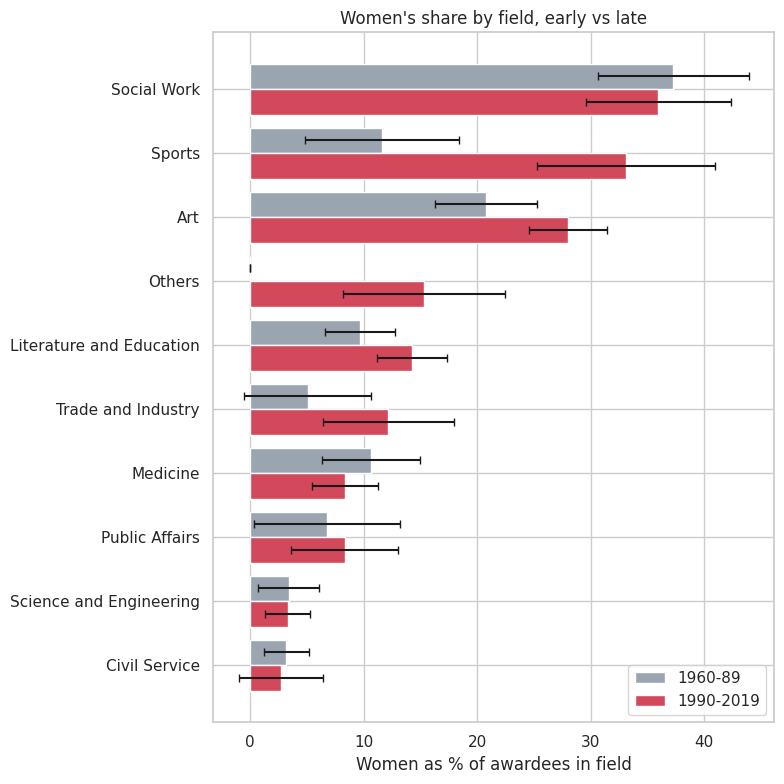

In [7]:
# from scipy.stats import norm, fisher_exact

df = df[df[AWARD_COL].isin(["Padma Shri", "Padma Bhushan", "Padma Vibhushan"])].copy()
FIELD_COL = "Field"                      # <- your field column

def two_prop_z(x1, n1, x2, n2):
    """H0: p1 = p2, H1: p2 > p1 (period 2 has higher women's share)."""
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    z = (p2 - p1) / np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    return p1, p2, z, 1 - norm.cdf(z)

# ---------- A. overall: pre-chosen comparisons ----------
def compare(d, a, b, label):
    A, B = d[d["decade"].isin(a)], d[d["decade"].isin(b)]
    p1, p2, z, p = two_prop_z(A["is_woman"].sum(), len(A), B["is_woman"].sum(), len(B))
    return {"comparison": label, "share_1": p1, "share_2": p2, "z0": z, "p_value": p}

overall_tests = pd.DataFrame([
    compare(df, [1960], [2010], "1960s vs 2010s"),
    compare(df, [1960], [1970], "1960s vs 1970s"),
    compare(df, [1980], [2010], "1980s vs 2010s"),
    compare(df, [1960, 1970, 1980], [1990, 2000, 2010], "1960-89 vs 1990-2019"),
])
display(overall_tests.round(4))

# ---------- B. per field: early (1960-89) vs late (1990-2019) ----------
df["period"] = np.where(df[YEAR_COL] < 1990, "early", "late")

rows = []
for f, d in df.groupby(FIELD_COL):
    e, l = d[d["period"] == "early"], d[d["period"] == "late"]
    x1, n1, x2, n2 = e["is_woman"].sum(), len(e), l["is_woman"].sum(), len(l)
    p1, p2, z, p_z = two_prop_z(x1, n1, x2, n2)
    pooled = (x1 + x2) / (n1 + n2)
    normal_ok = min(n1 * pooled, n1 * (1 - pooled), n2 * pooled, n2 * (1 - pooled)) >= 5
    _, p_f = fisher_exact([[x1, n1 - x1], [x2, n2 - x2]], alternative="less")
    rows.append({"field": f, "women_early": x1, "n_early": n1, "share_early": p1,
                 "women_late": x2, "n_late": n2, "share_late": p2,
                 "test_used": "z" if normal_ok else "Fisher",
                 "p_value": p_z if normal_ok else p_f})

field_tests = pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)
field_tests["significant_0.05"] = field_tests["p_value"] < 0.05
display(field_tests.round(4))

# ---------- plot: early vs late share per field with normal-approx 95% CI ----------
ft = field_tests.sort_values("share_late", ascending=False)
y = np.arange(len(ft))
ci = lambda p, n: 1.96 * np.sqrt(p * (1 - p) / n)

fig, ax = plt.subplots(figsize=(8, 0.6 * len(ft) + 2))
ax.barh(y - 0.2, ft["share_early"] * 100, 0.4, xerr=ci(ft["share_early"], ft["n_early"]) * 100,
        color="#9aa5b1", label="1960-89", capsize=3)
ax.barh(y + 0.2, ft["share_late"] * 100, 0.4, xerr=ci(ft["share_late"], ft["n_late"]) * 100,
        color="#d1495b", label="1990-2019", capsize=3)
ax.set_yticks(y)
ax.set_yticklabels(ft["field"])
ax.invert_yaxis()
ax.set(xlabel="Women as % of awardees in field", title="Women's share by field, early vs late")
ax.legend(title="")
plt.tight_layout()
plt.show()

**Reading section 4.1 (overall)**

| comparison | share 1 | share 2 | z₀ | p-value |
|---|---|---|---|---|
| 1960s vs 2010s | 9.5% | 18.8% | 4.84 | < 0.0001 |
| 1960s vs 1970s | 9.5% | 13.5% | 2.21 | 0.0137 |
| 1980s vs 2010s | 16.1% | 18.8% | 1.30 | 0.0966 |
| 1960–89 vs 1990–2019 | 13.0% | 17.8% | 4.28 | < 0.0001 |

H0 is rejected in the first, second and fourth rows, so women's share of awardees did rise. The biggest gain was early: from 9.5% in the 1960s to 16.1% in the 1980s. After that the share kept rising more slowly (15.9% in the 1990s, 17.7% in the 2000s, 18.8% in the 2010s). The 1980s vs 2010s comparison (16.1% vs 18.8%, p = 0.097) is not significant at 5%, but it is not far from it, so the later rise is suggestive and not established.

**Reading section 4.2 (by field)**

| field | share 1960–89 | share 1990–2019 | p-value (one-sided) | result at α = 0.05 |
|---|---|---|---|---|
| Sports | 11.6% | 33.1% | 0.0001 | increase |
| Art | 20.8% | 28.0% | 0.0077 | increase |
| Literature and Education | 9.7% | 14.3% | 0.0224 | increase |
| Trade and Industry | 5.1% | 12.2% | 0.0663 | not significant |
| Public Affairs | 6.8% | 8.3% | 0.4820 (Fisher) | not significant |
| Science and Engineering | 3.4% | 3.3% | 0.5229 | not significant |
| Social Work | 37.3% | 35.9% | 0.6099 | not significant |
| Civil Service | 3.2% | 2.7% | 0.7053 (Fisher) | not significant |
| Medicine | 10.7% | 8.3% | 0.8170 | not significant |
| Others | 0.0% | 15.3% | 0.8485 (Fisher) | not interpretable (1 awardee in 1960–89) |

- Only Sports, Art and Literature and Education show a significant increase within the field.
- A large p-value here means "no evidence of an increase", not "no change", because the test is one-sided. Medicine's share fell slightly (10.7% to 8.3%); a two-sided z-test (not in this notebook) gives p ≈ 0.37, so that fall is not significant.
- Trade and Industry rose from 5.1% to 12.2% (p = 0.066), just short of significance. With few women in the small fields the tests have little power.
- The x-axis of the bar chart is women as a percentage of **all awardees in that field** (women ÷ men + women), not a share of all women awardees. Social Work is about one-third women; Science and Engineering and Civil Service are below 5%.

## 5. Where do women's awards go?

Choosing between H1 and H2 depends on how women are distributed across fields, not only on their share within each field. Here the denominator is **all women awardees** in a period: a field's share is its women ÷ all women. The two periods are 1960–89 (230 women) and 1990–2019 (462 women). The tests are **two-sided**, because concentration and diversification point in opposite directions.

- **A. Each field.** H0: the probability that a woman awardee is in this field is the same in both periods. H1: it differs.
- **B. Top-2 concentration.** Take the two fields with the most women over 1960–2019 (Art and Social Work, chosen from the pooled data). H0: their combined share of women awardees is the same in both periods. H1: it differs.
- **C. Women vs men.** In each period, H0: women and men are equally likely to be awarded in those two fields. H1: they are not. These two fields were picked because many women are in them, so this comparison is partly circular, but the gap is large enough that the conclusion does not depend on it.
- **D. Descriptive only (no test).** Women's field mix by decade, the number of fields with at least one woman, and the top-2 share. Decade counts are small, so no p-values are given.

**Definition used.** "Diversified" means that the top-2 share fell and that more fields have women. Ross chapter 8 has no test for entropy-type measures, so none is used. The composition table is also saved as `women_field_composition.csv`.

Women awardees: 230 early (1960-89), 462 late (1990-2019)


,field,women_early,women_late,share_of_women_early_%,share_of_women_late_%,change_pp,test_used,p_value,significant_0.05
0,Art,65,185,28.2609,40.0433,11.7824,z,0.0024,True
1,Sports,10,46,4.3478,9.9567,5.6089,z,0.0108,True
2,Others,0,15,0.0000,3.2468,3.2468,Fisher,0.0037,True
3,Trade and Industry,3,15,1.3043,3.2468,1.9424,z,0.1305,False
4,Public Affairs,4,11,1.7391,2.3810,0.6418,Fisher,0.7833,False
5,Literature and Education,35,71,15.2174,15.3680,0.1506,z,0.9587,False
6,Science and Engineering,6,10,2.6087,2.1645,-0.4442,z,0.7142,False
7,Medicine,21,29,9.1304,6.2771,-2.8534,z,0.1720,False
8,Civil Service,10,2,4.3478,0.4329,-3.9149,Fisher,0.0005,True
9,Social Work,76,78,33.0435,16.8831,-16.1604,z,0.0000,True


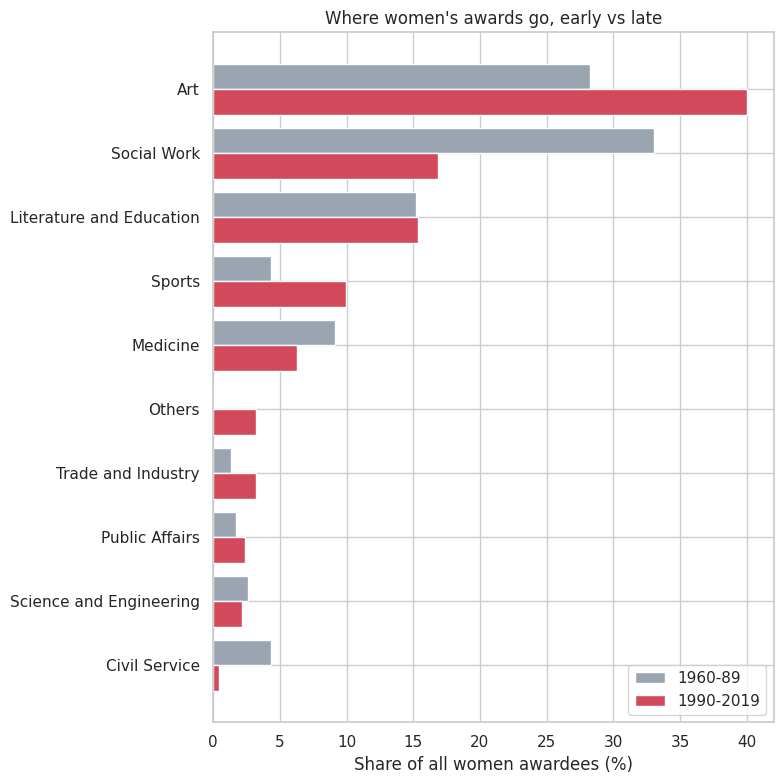


Top-2 fields by women awardees, 1960-2019: ['Art', 'Social Work']
Share of women awardees in these fields: early 61.3% -> late 56.9% (z test, z0 = -1.10, two-sided p = 0.2711)

Share of men vs women awardees who are in the top-2 fields:


,period,men_in_top2_%,women_in_top2_%,test_used,z0,p_value
0,early,24.4473,61.3043,z,11.4612,0.0
1,late,28.8398,56.9264,z,11.5647,0.0


,women,fields_with_a_woman,top2_share_%
decade,,,
1960,51,8,76.5
1970,102,8,61.8
1980,77,9,50.6
1990,73,10,61.6
2000,183,9,59.6
2010,206,10,52.9


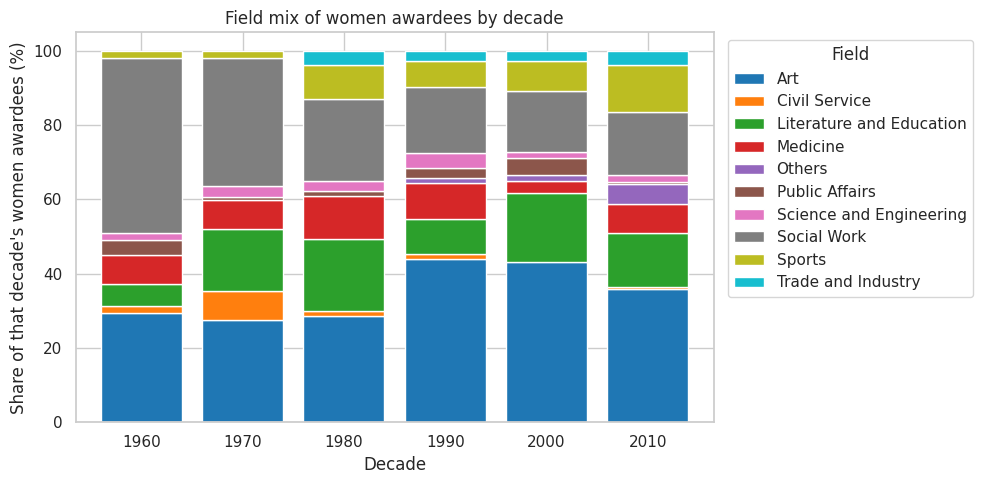

In [8]:
# ---------- Part 4: where do women's awards go? (Ross ch. 8 tests only) ----------
# from scipy.stats import norm, fisher_exact

df["period"] = np.where(df[YEAR_COL] < 1990, "early", "late")      # 1960-89 vs 1990-2019
women = df[df["is_woman"] == 1]

def two_prop_2s(x1, n1, x2, n2):
    """H0: p1 = p2, H1: p1 != p2. z test, or Fisher exact when counts are small."""
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    expected_ok = min(n1 * pooled, n1 * (1 - pooled), n2 * pooled, n2 * (1 - pooled)) >= 5
    if expected_ok:
        z = (p2 - p1) / np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
        return p1, p2, "z", z, 2 * (1 - norm.cdf(abs(z)))
    _, p = fisher_exact([[x1, n1 - x1], [x2, n2 - x2]], alternative="two-sided")
    return p1, p2, "Fisher", np.nan, p

# ---------- A. each field's share of ALL women awardees, early vs late ----------
comp = (women.groupby([FIELD_COL, "period"]).size().unstack(fill_value=0)
              .reindex(columns=["early", "late"], fill_value=0))
W1, W2 = comp["early"].sum(), comp["late"].sum()
print(f"Women awardees: {W1} early (1960-89), {W2} late (1990-2019)")

rows = []
for f in comp.index:
    p1, p2, test, z, p = two_prop_2s(comp.loc[f, "early"], W1, comp.loc[f, "late"], W2)
    rows.append({"field": f,
                 "women_early": comp.loc[f, "early"], "women_late": comp.loc[f, "late"],
                 "share_of_women_early_%": p1 * 100, "share_of_women_late_%": p2 * 100,
                 "change_pp": (p2 - p1) * 100,
                 "test_used": test, "p_value": p, "significant_0.05": p < 0.05})
composition = pd.DataFrame(rows).sort_values("change_pp", ascending=False).reset_index(drop=True)
display(composition.round(4))

c = composition.sort_values("share_of_women_late_%", ascending=False)
y = np.arange(len(c))
fig, ax = plt.subplots(figsize=(8, 0.6 * len(c) + 2))
ax.barh(y - 0.2, c["share_of_women_early_%"], 0.4, color="#9aa5b1", label="1960-89")
ax.barh(y + 0.2, c["share_of_women_late_%"], 0.4, color="#d1495b", label="1990-2019")
ax.set_yticks(y)
ax.set_yticklabels(c["field"])
ax.invert_yaxis()
ax.set(xlabel="Share of all women awardees (%)", title="Where women's awards go, early vs late")
ax.legend(title="")
plt.tight_layout()
plt.show()

# ---------- B. top-2 fields: did their share of women change? ----------
top_fields = comp.sum(axis=1).sort_values(ascending=False).head(2).index.tolist()
print("\nTop-2 fields by women awardees, 1960-2019:", top_fields)

x1, x2 = comp.loc[top_fields, "early"].sum(), comp.loc[top_fields, "late"].sum()
p1, p2, test, z, p = two_prop_2s(x1, W1, x2, W2)
print(f"Share of women awardees in these fields: early {p1:.1%} -> late {p2:.1%} "
      f"({test} test, z0 = {z:.2f}, two-sided p = {p:.4f})")

# ---------- C. women vs men: share of awardees in those same two fields ----------
rows = []
for per in ["early", "late"]:
    d = df[df["period"] == per]
    m, w = d[d["is_woman"] == 0], d[d["is_woman"] == 1]
    xm, xw = m[FIELD_COL].isin(top_fields).sum(), w[FIELD_COL].isin(top_fields).sum()
    pm, pw, test, z, p = two_prop_2s(xm, len(m), xw, len(w))
    rows.append({"period": per, "men_in_top2_%": pm * 100, "women_in_top2_%": pw * 100,
                 "test_used": test, "z0": z, "p_value": p})
print("\nShare of men vs women awardees who are in the top-2 fields:")
display(pd.DataFrame(rows).round(4))

# ---------- D. descriptive: women's field mix by decade ----------
mix = women.groupby(["decade", FIELD_COL]).size().unstack(fill_value=0)
summary = pd.DataFrame({
    "women": mix.sum(axis=1),
    "fields_with_a_woman": (mix > 0).sum(axis=1),
    "top2_share_%": mix[top_fields].sum(axis=1) / mix.sum(axis=1) * 100,
})
display(summary.round(1))

(mix.div(mix.sum(axis=1), axis=0) * 100).plot(kind="bar", stacked=True, figsize=(10, 5),
                                              colormap="tab10", width=0.8)
plt.ylabel("Share of that decade's women awardees (%)")
plt.xlabel("Decade")
plt.title("Field mix of women awardees by decade")
plt.xticks(rotation=0)
plt.legend(title="Field", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

composition.to_csv("women_field_composition.csv", index=False)

**Reading A (share of all women by field)**

| field | share of women 1960–89 | share of women 1990–2019 | change (points) | p-value | result |
|---|---|---|---|---|---|
| Art | 28.3% | 40.0% | +11.8 | 0.002 | gained share |
| Sports | 4.3% | 10.0% | +5.6 | 0.011 | gained share |
| Others | 0.0% | 3.2% | +3.2 | 0.004 | category appears late (see section 7) |
| Trade and Industry | 1.3% | 3.2% | +1.9 | 0.130 | not significant |
| Public Affairs | 1.7% | 2.4% | +0.6 | 0.783 | not significant |
| Literature and Education | 15.2% | 15.4% | +0.2 | 0.959 | not significant |
| Science and Engineering | 2.6% | 2.2% | −0.4 | 0.714 | not significant |
| Medicine | 9.1% | 6.3% | −2.9 | 0.172 | not significant |
| Civil Service | 4.3% | 0.4% | −3.9 | 0.000 | lost share |
| Social Work | 33.0% | 16.9% | −16.2 | ≈ 0 | lost share |

- The number of women awardees rose from 230 to 462 (+232). **Art (+120) and Sports (+36) account for about 67% of that increase**, and Literature and Education (+36) brings the three to about 83%. Social Work had 76 women in 1960–89 and 78 in 1990–2019.
- Because the shares sum to 100%, one field's gain is another's loss, so the Social Work drop is partly the mirror image of Art's rise.

**Reading B (top-2 concentration).** The share of women awardees in Art and Social Work was 61.3% in 1960–89 and 56.9% in 1990–2019 (z₀ = −1.1, two-sided p = 0.27). There is no evidence that concentration in these two fields changed between the periods.

**Reading C (women vs men).** In 1960–89, 24.4% of men but 61.3% of women were in these two fields; in 1990–2019 it was 28.8% of men and 56.9% of women (z₀ = 11.5 and 11.6; the p-value prints as 0.0 because of rounding and is far below 0.0001). Women are strongly concentrated in these two fields compared with men, in both periods.

**Reading D (by decade, descriptive)**

| decade | 1960s | 1970s | 1980s | 1990s | 2000s | 2010s |
|---|---|---|---|---|---|---|
| women awardees | 51 | 102 | 77 | 73 | 183 | 206 |
| fields with a woman (of 10) | 8 | 8 | 9 | 10 | 9 | 10 |
| top-2 share of women | 76.5% | 61.8% | 50.6% | 61.6% | 59.6% | 52.9% |
| Social Work share of women | 47.1% | 34.3% | 22.1% | 17.8% | 16.4% | 17.0% |
| Art share of women | 29.4% | 27.5% | 28.6% | 43.8% | 43.2% | 35.9% |

The top-2 share is highest in the 1960s and lower afterwards, but not steadily (50.6% in the 1980s, 61.6% in the 1990s). With 51–206 women per decade each percentage has a standard error of several points, so the dips and rebounds are partly noise. The stacked chart shows the same pattern: Social Work's share of women shrinks and Art's grows.

## 6. Verdict on the hypotheses

| Hypothesis | Verdict | Evidence |
|---|---|---|
| **H0** (no change) | **Rejected** | Women's share rose from 9.5% (1960s) to 18.8% (2010s), p < 0.0001; pooled 13.0% → 17.8%, p < 0.0001. Five of ten fields changed their share of women awardees. |
| **H3** (increase in every field, and diversified) | **Rejected** | Within-field share rose significantly in only three fields (Sports, Art, Literature and Education). Social Work (37.3% → 35.9%), Medicine, Civil Service, Public Affairs and Science and Engineering show no significant rise. |
| **H2** (diversified, but not increased in every field) | **Only partly supported** | Its second clause holds: the increase did not reach every field. Its first clause, diversification, has weak support: more fields have women (8 → 10 of 10) and Social Work's share of women fell (33.0% → 16.9%), but the top-2 share did not change significantly (p = 0.27). |
| **H1** (increased but concentrated in a few fields) | **Best supported** | The share increased; about 67% of the net rise in women awardees came from Art and Sports (83% with Literature and Education); about 57% of women awardees are in two fields against 29% of men. |

**Summary.** Women's representation did increase: from about 10% of awardees in the 1960s to about 19% in the 2010s, with most of the rise by the 1980s. The increase is concentrated in a few fields (mainly Art and Sports, with Literature and Education also significant), and women remain far more concentrated than men in two fields. H1 is the best fit of the four. H2 also fits in part, because the increase was not universal and the leading field moved from Social Work to Art, but diversification itself is not clearly shown. The count graphs in sections 2–3 can suggest diversification; the share-based tests above do not establish it.

## 7. Limitations

1. **Gender labels.** Names were checked (section 1), but not every label rests on a web page. 96 names were confirmed from a page; 1,753 were settled by recognising the person or an unambiguous given name; 3 could not be confirmed online and are labelled by name or recollection, and 1 was confirmed by the project author. Those 15 names are listed in `gender_overrides.csv` (`Source` = `name_only_unconfirmed`, or `knowledge_unconfirmed`):   Nekibuz Zaman (M); Shital Raj Mehta (M); Shriniwas (M); They could not be checked online because the search limit was reached, so they should be confirmed before the final report. About 2,100 names with a "Shri" honorific were treated as male without checking each one; one wrong label (Madhu Mansuri Hasmukh, a woman) was found among them, so a few more may remain. The labelling changed the results noticeably (section 1), so the numbers above should be read as good estimates, not exact counts.
2. **Share among awardees is not selection probability.** Without the pool of eligible women and men, the results describe who was awarded, not whether women's chance of selection changed.
3. **Independence.** Lists are decided yearly in batches and a person can receive more than one award, so awardees are not truly independent trials.
4. **Many tests, no correction.** Ten field tests are run in 4.2 and ten in 5A, each at α = 0.05, so one or two significant results could be false positives. The strongest results (p ≤ 0.008) are the Sports and Art increases in 4.2 and the Art, Sports, Civil Service and Social Work changes in 5A.
5. **Non-significant does not mean unchanged.** Counts of women in many fields are small, so the tests have low power.
6. **Shares sum to 100%.** In section 5, a gain for one field is necessarily a loss for others.
7. **"Others" is a catch-all label.** It has one awardee before 1990 and 98 after, which suggests a labelling change, so it should not be read as evidence of diversification.
8. **Civil Service shrank.** Its awards fell from 312 (1960–89) to 74 (1990–2019), so fewer women there partly reflects fewer awards in the field.
9. **Fixed split.** The early/late split at 1990 was chosen in advance, but other cut points were not tried.
10. **Fields and years.** Field labels are assigned by the awarding body. Sub-labels such as "Others- Agriculture" occur only in 2020–21, outside the tested years (1960–2019).